# Simulating the Fly Connectome as a Spiking Neural Network

This notebook takes the **male fly brain + ventral nerve cord connectome**
(the FlyWire / MCNS dataset — every neuron and every real synaptic connection
between them) and:

1. Loads and cleans the raw connectivity + neuron metadata
2. Converts it into a graph a computer can simulate (adjacency matrix)
3. Runs it as a **spiking neural network** (Leaky Integrate-and-Fire neurons),
   first naively (to show what goes wrong) and then properly tuned
4. Picks one real, identifiable neuron and traces its **upstream circuit**
   (what feeds into it) across multiple synaptic hops
5. Renders that circuit as an interactive graph

The example target neuron is **DNp02** (Root ID `10117`), a descending neuron
in the fly associated with visual escape / takeoff behavior — but the target
is a single variable you can swap for any other neuron in the dataset.

---


## 0. Setup

Install the extra packages we need beyond what's already in Colab
(`snntorch` for spiking neurons, `pyvis` for interactive graph rendering).


In [ ]:
!pip install snntorch pyvis -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 110.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

# Show all columns when we display dataframes, instead of truncating
pd.set_option('display.max_columns', None)

print("Setup complete.")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Setup complete.
PyTorch version: 2.11.0+cu128
CUDA available: True


## 1. Load the connectome data

Upload the dataset zip (e.g. `Male fly brain and spine.zip`) to this Colab
session first (the folder icon on the left → upload). It should contain, at minimum:

- `connections_princeton.csv.gz` — every synaptic connection: `pre_root_id`,
  `post_root_id`, `syn_count` (number of synapses), and (usually) neuropil /
  brain-region info
- `neurons.csv.gz` — per-neuron metadata: cell type, predicted neurotransmitter,
  brain region, nerve, etc.

Update `ZIP_PATH` below if your uploaded filename differs.


In [ ]:
ZIP_PATH = "/content/Male fly brain and spine.zip"
EXTRACT_DIR = "/content/MCNS_data"

!unzip -o "{ZIP_PATH}" -d "{EXTRACT_DIR}"
!gunzip -f "{EXTRACT_DIR}/connections_princeton.csv.gz"
!gunzip -f "{EXTRACT_DIR}/neurons.csv.gz"

print("\nExtracted files:")
!ls -la "{EXTRACT_DIR}"

Archive:  /content/Male fly brain and spine.zip
  inflating: /content/MCNS_data/connections_princeton.csv.gz  
  inflating: /content/MCNS_data/neurons.csv.gz  

Extracted files:
total 226688
drwxr-xr-x 2 root root      4096 Sep 12 14:33 .
drwxr-xr-x 1 root root      4096 Sep 12 14:33 ..
-rw-r--r-- 1 root root 213303979 Sep 12  2026 connections_princeton.csv
-rw-r--r-- 1 root root  18811758 Sep 12  2026 neurons.csv


In [ ]:
# Load the raw connection list (every synapse-level edge between neurons)
connections_df = pd.read_csv(f"{EXTRACT_DIR}/connections_princeton.csv")

print(f"Total connections: {len(connections_df):,}")
display(pd.concat([connections_df.head(5), connections_df.tail(5)]))

Total connections: 9,039,608


,pre_root_id,post_root_id,neuropil,syn_count,nt_type
0,10001,10091,EPA_R,1,NaN
1,10001,10091,GOR_R,4,NaN
2,10001,10106,CB_UNASGD,2,NaN
3,10001,10106,PVLP_R,3,NaN
4,10001,10106,SAD,4,NaN
9039603,1471062202,801190,LegNp_T2_L,5,NaN
9039604,1471062202,803934,LegNp_T2_L,7,NaN
9039605,1471062202,807436,LegNp_T2_L,6,NaN
9039606,1471062202,902278,LegNp_T2_L,6,NaN
9039607,1471062202,902427,LegNp_T2_L,5,NaN


In [ ]:
# Load the per-neuron metadata (cell type, neurotransmitter, region, etc.)
neurons_df = pd.read_csv(f"{EXTRACT_DIR}/neurons.csv")

print(f"Total neurons: {len(neurons_df):,}")
display(pd.concat([neurons_df.head(5), neurons_df.tail(5)]))

Total neurons: 166,700


,Root ID,Top in/out region,Community labels,Predicted NT type,Predicted NT confidence,Verified NT type,Verified Neuropeptide,Body Part,Function,Flow,Super Class,Class,Sub Class,Hemilineage,Nerve,Soma side,Primary Cell Type,Alternative Cell Type(s),Cable length (nm),Surface area (nm^2),Volume (nm^3)
0,10001,g10001,"hemibrainType: Giant Fiber,instance: DNp01(GF)...",ACH,0.50,NaN,NaN,NaN,NaN,NaN,descending_neuron,NaN,lt,putative_primary,NaN,right,DNp01,DNp01,NaN,NaN,NaN
1,10002,g10002,"hemibrainType: OCG01,statusLabel: Roughly traced",ACH,0.96,NaN,NaN,NaN,NaN,NaN,visual_projection,NaN,NaN,NaN,NaN,left,OCG01d,OCG01d,NaN,NaN,NaN
2,10003,g10003,statusLabel: Prelim Roughly traced,GABA,0.88,NaN,NaN,NaN,NaN,NaN,visual_centrifugal,NaN,NaN,putative_primary,NaN,right,VCH,VCH,NaN,NaN,NaN
3,10005,g10005,statusLabel: Roughly traced,GABA,0.84,NaN,NaN,NaN,NaN,NaN,cb_intrinsic,NaN,NaN,putative_primary,NaN,right,AOTU019,AOTU019,NaN,NaN,NaN
4,10006,g10006,"flywireType: VS1,VS2,VS3,VS4,VS5,VS6,VS7,VS8,s...",ACH,0.90,NaN,NaN,NaN,NaN,NaN,visual_projection,NaN,NaN,no_lineage,NaN,left,VS,VS,NaN,NaN,NaN
166695,1349927540,g,statusLabel: Reviewed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vnc_sensory,unknown_sensory,leg,NaN,NaN,NaN,SNxx33,SNxx33,NaN,NaN,NaN
166696,1387178136,g,statusLabel: Reviewed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vnc_sensory,mechanosensory_proprioceptive,hair_plate,NaN,NaN,NaN,SNpp45,SNpp45,NaN,NaN,NaN
166697,1399810824,g,statusLabel: Reviewed,ACH,0.94,NaN,NaN,NaN,NaN,NaN,vnc_sensory,mechanosensory_tactile,mechanosensory_bristle,NaN,NaN,NaN,SNta34,SNta34,NaN,NaN,NaN
166698,1434599043,g,statusLabel: Reviewed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vnc_sensory,mechanosensory_tactile,mechanosensory_bristle,NaN,NaN,NaN,SNta31,SNta31,NaN,NaN,NaN
166699,1471062202,g,statusLabel: Reviewed,ACH,0.87,NaN,NaN,NaN,NaN,NaN,vnc_sensory,mechanosensory_proprioceptive,hair_plate,NaN,NaN,NaN,SNpp45,SNpp45,NaN,NaN,NaN


## 2. Assign excitatory / inhibitory polarity

Real neurons aren't just "connected" — each connection is either **excitatory**
(pushes the downstream neuron toward firing) or **inhibitory** (pushes it away).
In flies, this is well approximated by neurotransmitter identity: neurons that
release **GABA are inhibitory**; most everything else (acetylcholine,
glutamate*, etc. in this simplified scheme) we treat as **excitatory**.

*Glutamate is technically often inhibitory in insects too, but we keep this
binary and simple here — feel free to refine `assign_polarity` if you want a
more biologically careful mapping (e.g. also treating glutamatergic neurons as
inhibitory).

We then merge this polarity onto every connection, based on the *pre-synaptic*
neuron (the sender), since polarity is a property of the sending neuron's
neurotransmitter release, not the receiving neuron.


In [ ]:
def assign_polarity(nt_type):
    """Map a predicted neurotransmitter to a synaptic sign.
    -1 = inhibitory (GABAergic), +1 = excitatory (everything else / unknown).
    """
    if pd.isna(nt_type):
        return 1  # default to excitatory if unknown
    if 'gaba' in str(nt_type).lower():
        return -1
    return 1

neurons_df['polarity'] = neurons_df['Predicted NT type'].apply(assign_polarity)

print("Polarity breakdown across all neurons:")
print(neurons_df['polarity'].value_counts().rename({1: 'Excitatory (+1)', -1: 'Inhibitory (-1)'}))

Polarity breakdown across all neurons:
polarity
Excitatory (+1)    146469
Inhibitory (-1)     20231
Name: count, dtype: int64


In [ ]:
# Merge the PRE-synaptic neuron's polarity and neurotransmitter onto each connection.
# We drop the existing (empty) nt_type column from connections_df first to avoid
# a naming collision, then bring in the correct values from neurons_df.
network_df = pd.merge(
    connections_df.drop(columns=['nt_type'], errors='ignore'),
    neurons_df[['Root ID', 'polarity', 'Predicted NT type']],
    left_on='pre_root_id',
    right_on='Root ID',
    how='left'
).rename(columns={'Predicted NT type': 'pre_nt_type'})

# Also bring in useful metadata (Super Class, neuropil, etc.) for later filtering/coloring.
# Adjust the column list below to whatever your neurons.csv actually contains.
meta_cols = [c for c in ['Root ID', 'Super Class', 'Class', 'Primary Cell Type',
                          'Body Part', 'Nerve'] if c in neurons_df.columns]
network_df = pd.merge(
    network_df,
    neurons_df[meta_cols],
    left_on='pre_root_id',
    right_on='Root ID',
    how='left',
    suffixes=('', '_pre')
)

print(f"network_df shape: {network_df.shape}")
display(network_df.head())

network_df shape: (9039608, 13)


,pre_root_id,post_root_id,neuropil,syn_count,Root ID,polarity,pre_nt_type,Root ID_pre,Super Class,Class,Primary Cell Type,Body Part,Nerve
0,10001,10091,EPA_R,1,10001,1,ACH,10001,descending_neuron,NaN,DNp01,NaN,NaN
1,10001,10091,GOR_R,4,10001,1,ACH,10001,descending_neuron,NaN,DNp01,NaN,NaN
2,10001,10106,CB_UNASGD,2,10001,1,ACH,10001,descending_neuron,NaN,DNp01,NaN,NaN
3,10001,10106,PVLP_R,3,10001,1,ACH,10001,descending_neuron,NaN,DNp01,NaN,NaN
4,10001,10106,SAD,4,10001,1,ACH,10001,descending_neuron,NaN,DNp01,NaN,NaN


## 3. Convert to a PyTorch adjacency matrix

FlyWire "Root IDs" are massive 15-digit numbers — not usable directly as
tensor indices. We map every unique neuron to a simple, contiguous integer
`0, 1, 2, ...N-1`, and keep a reverse lookup (`idx_to_node`) so we can always
translate a simulation result back to a real, biological neuron.

The resulting **adjacency matrix `W`** is an `N x N` sparse matrix where
`W[i, j]` is the (signed) synaptic weight from neuron `i` to neuron `j`
(synapse count × polarity of neuron `i`).


In [ ]:
# Every unique neuron that appears as either a sender or receiver
unique_nodes = pd.unique(network_df[['pre_root_id', 'post_root_id']].values.ravel('K'))
node_to_idx = {node: idx for idx, node in enumerate(unique_nodes)}
idx_to_node = {idx: node for node, idx in node_to_idx.items()}  # reverse lookup

num_neurons = len(unique_nodes)
print(f"Total unique neurons in the graph: {num_neurons:,}")

Total unique neurons in the graph: 165,836


In [ ]:
# Map raw biological IDs -> tensor indices for every edge
src_indices = network_df['pre_root_id'].map(node_to_idx).values
dst_indices = network_df['post_root_id'].map(node_to_idx).values

# Signed synapse weight = synapse count * sender polarity (+1 or -1)
weights = network_df['syn_count'].values * network_df['polarity'].fillna(1).values

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

indices = torch.tensor(np.vstack([src_indices, dst_indices]), dtype=torch.long)
values = torch.tensor(weights, dtype=torch.float32)

adjacency_matrix = torch.sparse_coo_tensor(
    indices, values, size=(num_neurons, num_neurons), device=device
).coalesce()

print(f"Adjacency matrix: {adjacency_matrix.shape}, on device: {device}")
print(f"Non-zero entries: {adjacency_matrix._nnz():,}")

/tmp/ipykernel_857/2836971896.py:13: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  adjacency_matrix = torch.sparse_coo_tensor(


Adjacency matrix: torch.Size([165836, 165836]), on device: cuda
Non-zero entries: 6,242,118


## 4. First attempt: naive simulation (this will explode)

Now we run the connectome as a **spiking neural network**, using
[`snntorch`](https://snntorch.readthedocs.io/)'s Leaky Integrate-and-Fire (LIF)
neuron model. Each of the `num_neurons` nodes is one LIF unit; at every
timestep, its membrane potential is updated based on the incoming spikes
from the previous timestep, weighted by the real (raw) synapse counts.

**On purpose, this first version uses the raw, unscaled synapse counts.**
Real synapse counts range from 1 to 100+ per connection — far larger than the
small input currents LIF models are normally tuned for. The result is
**runaway excitation**: once a few neurons fire, they trigger enormous input
currents downstream, and within a handful of timesteps the entire network is
firing on every step. This is a common and instructive failure mode when you
plug real biological weights into a simulation without rescaling them.


In [ ]:
import snntorch as snn

def run_lif_simulation(W, num_neurons, beta, threshold, num_steps, device,
                        stim_indices=None, stim_current=5.0):
    """Run a simple LIF simulation over a weighted adjacency matrix W.

    Returns:
        spike_record: list of (num_neurons,) tensors, one per timestep,
                       giving which neurons fired (1) or not (0).
    """
    lif = snn.Leaky(beta=beta, threshold=threshold)
    mem = torch.zeros(1, num_neurons, device=device)
    spk_out = torch.zeros(1, num_neurons, device=device)

    spike_record = []

    for step in range(num_steps):
        # Input current = spikes from the previous step, propagated through
        # the weighted adjacency matrix (who's connected to whom, and how strongly)
        input_current = torch.sparse.mm(W.t(), spk_out.T).T

        # Optional: inject an external stimulus into specific neurons on step 0,
        # to kick off activity from a known starting point rather than nothing.
        if stim_indices is not None and step == 0:
            input_current[0, stim_indices] += stim_current

        spk_out, mem = lif(input_current, mem)
        spike_record.append(spk_out.squeeze(0).clone())

    return spike_record


def plot_spike_activity(spike_record, title):
    total_spikes_per_step = [s.sum().item() for s in spike_record]
    plt.figure(figsize=(9, 4))
    plt.plot(total_spikes_per_step, color='crimson')
    plt.xlabel("Timestep")
    plt.ylabel("Total neurons firing")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()
    return total_spikes_per_step

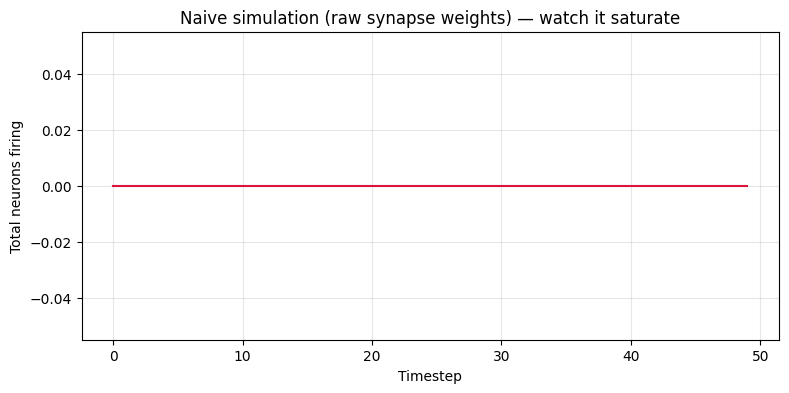

In [ ]:
# --- Naive run: raw synapse counts, no scaling ---
NUM_STEPS = 50

spike_record_naive = run_lif_simulation(
    W=adjacency_matrix,
    num_neurons=num_neurons,
    beta=0.85,
    threshold=5.0,
    num_steps=NUM_STEPS,
    device=device,
)

_ = plot_spike_activity(
    spike_record_naive,
    "Naive simulation (raw synapse weights) — watch it saturate"
)

Notice the total spike count shoots up almost immediately and pins near
`num_neurons` — essentially every neuron is firing on every timestep. That's
not biologically meaningful activity; it's numerical saturation. This happens
because raw synapse counts (which can be 50, 100+) are treated directly as
input current, dwarfing the LIF threshold almost instantly once any spikes
occur.


## 5. Second attempt: scaled and properly tuned

To get meaningful dynamics, we need the input current from a firing neuron to
be on a similar scale to the firing threshold — not orders of magnitude
larger. We do this by:

1. **Scaling down the synapse weights** (`weight_scale`) so a single spike
   contributes a small, reasonable current rather than a massive one.
2. **Raising the threshold** so a neuron needs a meaningful number of
   simultaneous inputs to fire (mimicking real synaptic integration).
3. **Lowering `beta`** slightly (faster membrane leak) so charge doesn't
   accumulate indefinitely across timesteps.

These are the same three knobs (`weight_scale`, `beta`, `threshold`) you'll
want to hand-tune for your own dataset/hardware — there's no universally
"correct" value, since it depends on the actual distribution of synapse
counts in your data.


In [ ]:
# Inspect the raw weight distribution first — this tells us how aggressively
# we need to scale things down.
raw_weights = adjacency_matrix.values().abs()
print("Raw signed synapse-weight magnitude distribution:")
print(f"  min:    {raw_weights.min().item():.1f}")
print(f"  median: {raw_weights.median().item():.1f}")
print(f"  mean:   {raw_weights.mean().item():.2f}")
print(f"  max:    {raw_weights.max().item():.1f}")

Raw signed synapse-weight magnitude distribution:
  min:    5.0
  median: 9.0
  mean:   14.40
  max:    2591.0


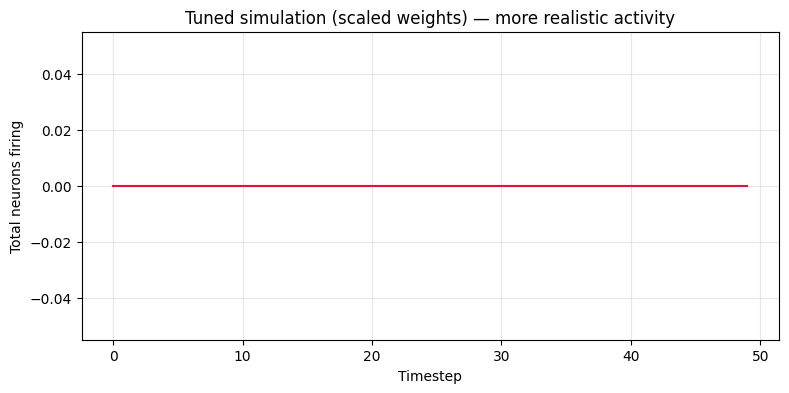

Average neurons firing per step: 0.0 (0.00% of network)


In [ ]:
# --- Stable run: scaled weights + tuned LIF parameters ---
weight_scale = 0.02      # shrink raw synapse counts to a sane current scale
beta_stable = 0.75       # faster membrane leak
threshold_stable = 0.5   # how much accumulated current it takes to fire

W_scaled = torch.sparse_coo_tensor(
    adjacency_matrix.indices(),
    adjacency_matrix.values() * weight_scale,
    size=adjacency_matrix.shape,
    device=device
).coalesce()

spike_record_stable = run_lif_simulation(
    W=W_scaled,
    num_neurons=num_neurons,
    beta=beta_stable,
    threshold=threshold_stable,
    num_steps=NUM_STEPS,
    device=device,
)

totals_stable = plot_spike_activity(
    spike_record_stable,
    "Tuned simulation (scaled weights) — more realistic activity"
)
print(f"Average neurons firing per step: {np.mean(totals_stable):.1f} "
      f"({100*np.mean(totals_stable)/num_neurons:.2f}% of network)")

If activity still saturates or dies out completely, treat `weight_scale`,
`beta`, and `threshold` as a small grid search — e.g. try
`weight_scale` in `[0.05, 0.02, 0.01, 0.005, 0.002]` and `threshold` in
`[0.3, 0.5, 1.0, 2.0]`, and look for a setting where spike activity is
non-zero but doesn't immediately saturate the whole network.


In [ ]:
# Optional: quick sweep to help you find a stable regime.
# Uncomment and run if the settings above still saturate or die out.

# results = {}
# for ws in [0.05, 0.02, 0.01, 0.005]:
#     for th in [0.3, 0.5, 1.0, 2.0]:
#         W_test = torch.sparse_coo_tensor(
#             adjacency_matrix.indices(),
#             adjacency_matrix.values() * ws,
#             size=adjacency_matrix.shape,
#             device=device
#         ).coalesce()
#         rec = run_lif_simulation(W_test, num_neurons, beta=0.75, threshold=th,
#                                   num_steps=30, device=device)
#         avg_active = np.mean([s.sum().item() for s in rec])
#         results[(ws, th)] = avg_active
#         print(f"weight_scale={ws:<6} threshold={th:<5} -> avg firing/step={avg_active:.1f} "
#               f"({100*avg_active/num_neurons:.2f}%)")

## 6. Translate a simulated neuron back to biology

The simulation only knows integer indices (`0..N-1`). To make sense of any
particular neuron's activity, we translate its tensor index back to its real
FlyWire Root ID and look up its full metadata.


In [ ]:
# Pick any tensor index you're curious about (e.g. one that fired a lot above)
target_index = 103

biological_root_id = idx_to_node[target_index]
print(f"Tensor index {target_index} corresponds to FlyWire Root ID: {biological_root_id}\n")

neuron_metadata = neurons_df[neurons_df['Root ID'] == biological_root_id]

columns_to_view = [c for c in [
    'Root ID', 'Super Class', 'Class', 'Primary Cell Type',
    'Predicted NT type', 'Body Part', 'Nerve'
] if c in neurons_df.columns]

display(neuron_metadata[columns_to_view].T)

Tensor index 103 corresponds to FlyWire Root ID: 10117



,103
Root ID,10117
Super Class,descending_neuron
Class,NaN
Primary Cell Type,DNp02
Predicted NT type,ACH
Body Part,NaN
Nerve,NaN


## 7. Choose a target neuron to investigate

Everything below traces and visualizes the circuit **around one specific,
named neuron**. The example is `DNp02`, a descending neuron implicated in
visual escape / takeoff behavior in flies (Root ID `10117`).

**To investigate a different neuron, just change `TARGET_ROOT_ID` below** —
everything downstream (local sub-graph, multi-hop trace, visualization) will
automatically use the new value. You can look up Root IDs for named cell
types via the `neurons_df` metadata table above (filter by `Primary Cell Type`
or `Class`).


In [ ]:
# ============================================================
# CHANGE THIS to investigate a different neuron
# ============================================================
TARGET_ROOT_ID = 10117   # DNp02 — descending neuron, escape/takeoff behavior
TARGET_LABEL = "DNp02"   # just a human-readable label for titles/print statements
# ============================================================

print(f"Target neuron: {TARGET_LABEL} (Root ID: {TARGET_ROOT_ID})")
display(neurons_df[neurons_df['Root ID'] == TARGET_ROOT_ID][columns_to_view].T)

Target neuron: DNp02 (Root ID: 10117)


,103
Root ID,10117
Super Class,descending_neuron
Class,NaN
Primary Cell Type,DNp02
Predicted NT type,ACH
Body Part,NaN
Nerve,NaN


## 8. Extract the target neuron's immediate local circuit

Before tracing multiple hops, let's look at the neuron's **direct** neighbors:
everything that synapses directly onto it (inputs) and everything it directly
synapses onto (outputs). We cap each side at 30 connections just to keep the
visualization readable — the full connection lists are usually much larger.


In [ ]:
incoming_edges = network_df[network_df['post_root_id'] == TARGET_ROOT_ID]
outgoing_edges = network_df[network_df['pre_root_id'] == TARGET_ROOT_ID]

print(f"{TARGET_LABEL} has {len(incoming_edges):,} total incoming connections "
      f"and {len(outgoing_edges):,} total outgoing connections in the dataset.")

# Sample a readable subset for visualization
sub_in = incoming_edges.head(30)
sub_out = outgoing_edges.head(30)
sub_graph_df = pd.concat([sub_in, sub_out])

print(f"Using {len(sub_graph_df)} local connections for the visualization below.")

DNp02 has 539 total incoming connections and 415 total outgoing connections in the dataset.
Using 60 local connections for the visualization below.


In [ ]:
from pyvis.network import Network

def build_pyvis_network(edge_df, target_id, target_label,
                         height="750px", width="100%"):
    net = Network(height=height, width=width, bgcolor="#1a1a1a",
                   font_color="white", directed=True, cdn_resources="in_line")
    net.force_atlas_2based(gravity=-2500, central_gravity=0.01, spring_length=100)

    added_nodes = set()

    for _, row in edge_df.iterrows():
        pre = str(row['pre_root_id'])
        post = str(row['post_root_id'])
        weight = row['syn_count']

        for node_id in (pre, post):
            if node_id not in added_nodes:
                is_target = (node_id == str(target_id))

                # Look up metadata for this neuron to build a hover tooltip
                meta = neurons_df[neurons_df['Root ID'] == int(node_id)]
                if not meta.empty:
                    m = meta.iloc[0]
                    tooltip = (
                        f"Root ID: {node_id}<br>"
                        f"Cell Type: {m.get('Primary Cell Type', 'Unknown')}<br>"
                        f"Class: {m.get('Class', 'Unknown')}<br>"
                        f"Super Class: {m.get('Super Class', 'Unknown')}<br>"
                        f"Neurotransmitter: {m.get('Predicted NT type', 'Unknown')}"
                    )
                else:
                    tooltip = f"Root ID: {node_id}"

                net.add_node(
                    node_id,
                    label=target_label if is_target else node_id,
                    title=tooltip,
                    color="#ff4d4d" if is_target else "#4da6ff",
                    size=25 if is_target else 12,
                )
                added_nodes.add(node_id)

        edge_color = "#00cc66" if row.get('polarity', 1) == 1 else "#cc33ff"
        net.add_edge(pre, post, value=int(weight),
                     title=f"Synapses: {int(weight)}", color=edge_color,
                     arrows="to")

    return net

In [ ]:
net_local = build_pyvis_network(sub_graph_df, TARGET_ROOT_ID, TARGET_LABEL)
net_local.save_graph(f"{TARGET_LABEL}_local_circuit.html")

from IPython.display import IFrame
IFrame(f"{TARGET_LABEL}_local_circuit.html", width="100%", height=770)

## 9. Trace multi-hop upstream pathways

A neuron's *direct* inputs are only part of the story — often what really
drives behavior is a chain of neurons several synapses upstream. Here we walk
backward from the target neuron, hop by hop: at each hop, we find every
neuron that synapses onto anything in our current "frontier," add those
edges to the trace, and expand the frontier to include those new upstream
neurons.

`MAX_HOPS` controls how far back we trace. Each additional hop can pull in
many more neurons, so raise it gradually — 2–3 hops is usually enough to see
interesting structure without the graph becoming unreadable.


In [ ]:
MAX_HOPS = 2

print(f"Tracing {MAX_HOPS}-hop upstream pathways leading to {TARGET_LABEL} "
      f"({TARGET_ROOT_ID})...")

current_target_ids = {TARGET_ROOT_ID}
all_traced_edges = []

for hop in range(1, MAX_HOPS + 1):
    upstream_edges = network_df[network_df['post_root_id'].isin(current_target_ids)]

    if upstream_edges.empty:
        print(f"No further upstream connections found at hop {hop}.")
        break

    all_traced_edges.append(upstream_edges)
    current_target_ids = set(upstream_edges['pre_root_id'].unique())
    print(f"Hop {hop}: found {len(upstream_edges):,} connections, "
          f"{len(current_target_ids):,} unique upstream neurons.")

pathway_df = pd.concat(all_traced_edges, ignore_index=True) if all_traced_edges else pd.DataFrame()
print(f"\nTotal traced edges across {MAX_HOPS} hops: {len(pathway_df):,}")

### A note on graph size

Multi-hop traces on dense biological networks can grow **very** quickly
(each hop can multiply the neuron count several-fold). If `pathway_df` above
is huge (tens of thousands of rows), the visualization below will be slow or
unreadable. Consider filtering `pathway_df` down — e.g. keep only edges above
a minimum `syn_count`, or only the top-N strongest inputs at each hop —
before rendering.


In [ ]:
# Optional: filter to only reasonably strong connections before visualizing,
# if the traced pathway is very large. Adjust or skip as needed.
MIN_SYNAPSE_COUNT = 1   # raise this (e.g. to 5 or 10) to prune weak connections

pathway_df_filtered = pathway_df[pathway_df['syn_count'] >= MIN_SYNAPSE_COUNT]
print(f"Edges after filtering (syn_count >= {MIN_SYNAPSE_COUNT}): {len(pathway_df_filtered):,}")

## 10. Visualize the full upstream pathway

Same rendering approach as the local circuit above, but now covering every
edge in the multi-hop trace. The target neuron is highlighted in red;
everything upstream is blue. Edge color still encodes excitatory (green) vs.
inhibitory (purple), based on the sending neuron's predicted neurotransmitter.


In [ ]:
net_pathway = build_pyvis_network(
    pathway_df_filtered, TARGET_ROOT_ID, TARGET_LABEL,
    height="850px"
)
net_pathway.save_graph(f"{TARGET_LABEL}_upstream_pathway.html")

from IPython.display import IFrame
IFrame(f"{TARGET_LABEL}_upstream_pathway.html", width="100%", height=870)

## Summary

- Loaded the real fly connectome (neurons + weighted, signed synaptic connections)
- Converted it into a PyTorch sparse adjacency matrix
- Simulated it as a spiking neural network, showing why raw synapse counts
  cause runaway excitation, and how scaling + threshold tuning fixes that
- Traced the full upstream circuitry feeding into a real, named neuron
  (`DNp02` by default) across multiple synaptic hops
- Rendered that circuit interactively

**Where to go from here:**
- Swap `TARGET_ROOT_ID` to explore a different neuron or circuit
- Try downstream tracing (swap `post_root_id`/`pre_root_id` in the hop loop)
  to see what a neuron *drives*, rather than what drives it
- Inject stimulus into a specific sensory neuron (via `stim_indices` in
  `run_lif_simulation`) and watch which downstream neurons respond
- Compare simulated firing patterns against `Super Class` / `Primary Cell Type`
  to see whether particular functional groups activate together
